# A Library RAG Lab: Follow the Evidence

This lesson follows one question:

> How many books can a student borrow at a time, for how long, and how can they renew them?

Open the [two-page Library Borrowing Guide](../data/library-guide.pdf) and find the answer yourself. Then watch the program do the same job: **organize the material for retrieval, find the evidence, and ask a model to compose an answer.**

We will follow just two pieces of evidence throughout the lesson. You do not need to memorize every field or API name.

| Evidence to follow | Location in the PDF | Part of the question it answers |
| --- | --- | --- |
| **Table evidence:** 3 books, 14 days | Page 1 | How many books? For how long? |
| **Text evidence:** renew once for 7 extra days if nobody else has reserved the book | Page 2 | How does renewal work? What are the conditions? |

**How to use this lesson:** On your first pass, read the explanations, diagrams, and saved results. Predict each check's answer before opening its explanation. On your second pass, run the code from top to bottom and look only for each step's observation targets. Long functions and outputs are collapsed by default; expand them when needed.

Sections 1–3 prepare the components, sections 4–6 build the index, sections 7–9 unpack the question-answering process, and section 10 covers saving and rerunning. See the [README](../README.md) for installation and startup. Rerunning ingestion or queries can call cloud models; reading saved results does not call a model.

## Start with a map; you do not need to memorize every arrow

```mermaid
flowchart TD
    subgraph INDEX["Phase 1: Ingest the document and build reusable indexes"]
        PDF["Two-page library PDF"] --> PARSE["Docling parses text, a table, and an image"]
        PARSE --> CHUNKS["Split text; describe the table and image"]
        CHUNKS --> TEXT["Store chunk content and provenance"]
        CHUNKS --> VECTOR["Generate chunk embeddings"]
        CHUNKS --> GRAPH["Extract entities and relationships; build graph and vector indexes"]
    end
    subgraph QUERY["Phase 2: Retrieve evidence and answer a question"]
        Q["How many books, for how long, and how to renew?"] --> SEARCH["mix: vector and graph retrieval"]
        SEARCH --> EVIDENCE["Retrieve relevant chunks and combine evidence"]
        EVIDENCE --> PROMPT["Instructions + evidence + original question"]
        PROMPT --> ANSWER["Answer: 3 books, 14 days, renewal steps and conditions"]
        ANSWER --> REF["Include source references"]
    end
    VECTOR --> SEARCH
    GRAPH --> SEARCH
    TEXT --> EVIDENCE
```

**Ingestion can finish before any question arrives.** Parsing a PDF and building an index do not train or change the answer model. We will add caching to this main path in section 9.

By the end, you should be able to explain three things without reading the code:

1. How do “3 books” and “14 days” travel from the PDF table into the answer?
2. What do vectors and the knowledge graph each help the system find?
3. Which model call is avoided when a repeated question hits the cache?

“Saved results” refers to the run stored in this notebook. If you ingest the document again, model descriptions, graph contents, and some IDs may change. Use the new outputs as the source of truth.

## 1. Prepare: Locate the source and choose a storage directory

**Question for this step: Which file will the program read, and where will it save the index?** No parsing, ingestion, or querying has happened yet.

| Setting | Meaning in this lesson |
| --- | --- |
| `pdf_path` | The source file, `data/library-guide.pdf` |
| `parsed_dir` | Files and images exported by Docling |
| `storage_dir` | Persistent chunks, vectors, graph, and caches |
| Model names, endpoint, and dimensions | Which cloud models receive which tasks |

Start JupyterLab from the project root with `src/.env` loaded. The code searches upward for the directory containing `pyproject.toml`, so it can locate the PDF even when the notebook is inside `src/`.

**After running, check only:** the source filename is `library-guide.pdf`, and the index directory is `outputs/library_rag_storage`. You do not need to study every import yet.

In [1]:
import os
from collections import Counter
from pathlib import Path

from IPython.display import Image, Markdown, display
from lightrag import QueryParam
from lightrag.llm.openai import openai_complete_if_cache, openai_embed
from lightrag.utils import EmbeddingFunc
from raganything import RAGAnything, RAGAnythingConfig

cwd = Path.cwd().resolve()
project_dir = next((path for path in (cwd, *cwd.parents) if (path / "pyproject.toml").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Project root not found. Start JupyterLab from the project root.")

pdf_path = project_dir / "data/library-guide.pdf"
parsed_dir = project_dir / "outputs/parsed"
storage_dir = project_dir / "outputs/library_rag_storage"

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("OPENAI_BASE_URL")
llm_model = os.getenv("LLM_MODEL")
vision_model = os.getenv("VISION_MODEL")
embedding_model = os.getenv("EMBEDDING_MODEL")
embedding_dim = int(os.getenv("EMBEDDING_DIM"))

print(f"Source file: {pdf_path.name}")
print(f"Parser output directory: {parsed_dir}")
print(f"Index directory: {storage_dir}")
print(f"Text: {llm_model}, vision: {vision_model}, embedding: {embedding_model} ({embedding_dim} dimensions)")

Source file: library-guide.pdf
Parser output directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed
Index directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
Text: gpt-6-luna, vision: gpt-6-luna, embedding: text-embedding-3-small (1536 dimensions)


## 2. Prepare: Separate the three model roles

**Question for this step: Who interprets content, and who turns text into numbers?** The next cell only defines callback functions. Defining them does not send a model request.

```mermaid
flowchart LR
    T["Text, table structure, or an extraction task"] --> L["llm: text model"] --> O["Analysis, entities, relationships, keywords, or an answer"]
    I["Image and related text"] --> V["vision: vision model"] --> D["Text description of the image"]
    S["A batch of texts"] --> E["embed: embedding model"] --> N["One numeric vector per text"]
```

`calls` is the current kernel's **model call log**. Each callback records its input and output so that we can inspect what happened. It is not the persistent cache; resetting this list does not clear cached results on disk.

**Remember these roles:** `llm` interprets and generates text; `vision` interprets images; `embed` encodes text. The text model extracts entities and relationships. Embedding alone does not build a graph or write a summary.

The callback implementations are long and are collapsed by default. On your first pass, run the cell and use `calls` later to inspect the work.

<details>
<summary>Optional detail: Why are these functions relatively long?</summary>

They both call the official OpenAI helper functions and record inputs and outputs. Vision records show image types and URL lengths; section 4 displays the actual image. Embedding records show input texts, the output shape, and the first six coordinates of the first vector. The next section uses `EmbeddingFunc` to declare the model and dimensions; `openai_embed.func` passes the configured dimensions to the API.

</details>

In [2]:
calls = []


async def llm(prompt, system_prompt=None, history_messages=None, **kwargs):
    call = {
        "kind": "llm",
        "model": llm_model,
        "prompt": prompt,
        "system_prompt": system_prompt,
        "history_messages": history_messages or [],
        "keyword_extraction": kwargs.get("keyword_extraction", False),
    }
    calls.append(call)
    output = await openai_complete_if_cache(
        llm_model, prompt, system_prompt=system_prompt,
        history_messages=history_messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output


async def vision(prompt, system_prompt=None, image_data=None, messages=None, **kwargs):
    # Image ingestion passes base64-encoded Docling PNG data; image-enhanced queries pass full messages.
    if messages is None:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        content = prompt
        if image_data:
            content = [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_data}"}},
            ]
        messages.append({"role": "user", "content": content})

    summary = []
    image_count = 0
    for message in messages:
        content = message["content"]
        if isinstance(content, list):
            parts = []
            for part in content:
                if part["type"] == "image_url":
                    parts.append({"type": "image_url", "url_chars": len(part["image_url"]["url"])})
                    image_count += 1
                else:
                    parts.append(part)
            content = parts
        summary.append({"role": message["role"], "content": content})

    call = {"kind": "vision", "model": vision_model, "messages": summary, "images": image_count}
    calls.append(call)
    output = await openai_complete_if_cache(
        vision_model, "", messages=messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output


async def embed(texts):
    call = {"kind": "embed", "model": embedding_model, "texts": list(texts)}
    calls.append(call)
    vectors = await openai_embed.func(
        texts, model=embedding_model, base_url=base_url, api_key=api_key,
        embedding_dim=embedding_dim, max_token_size=8192,
    )
    call["output"] = {"shape": vectors.shape, "first_vector_sample": vectors[0, :6].tolist()}
    return vectors

## 3. Prepare: Connect the components through RAGAnything

**Question for this step: Who connects the parser, models, and indexes?**

| Component | Role in this lesson |
| --- | --- |
| Docling | Recognizes text, a table, and an image in the PDF |
| RAGAnything | Coordinates multimodal processing and sends content through ingestion and querying |
| LightRAG | Splits text, manages vector and graph indexes, retrieves evidence, and coordinates answer generation |

This project uses LightRAG, which follows a graph-assisted retrieval approach. It does not separately invoke Microsoft's GraphRAG package.

**Before running, notice two settings:** `chunk_token_size=75` and `chunk_overlap_token_size=20`. They will determine how the ordinary text becomes overlapping chunks. A token is a unit used by a model's tokenizer; it is not necessarily a whole word or character.

The next cell creates `rag` and selects English prompts. It does not ingest the PDF yet. On your first pass, just confirm the `docling` parser, the three model callbacks, and the 75/20 chunking settings. We will inspect their effect in section 5.

In [3]:
from raganything import set_prompt_language

set_prompt_language("en")

config = RAGAnythingConfig(
    parser="docling",
    parser_output_dir=str(parsed_dir),
    working_dir=str(storage_dir),
    display_content_stats=False,
)

rag = RAGAnything(
    config=config,
    llm_model_func=llm,
    vision_model_func=vision,
    embedding_func=EmbeddingFunc(
        embedding_dim=embedding_dim,
        max_token_size=8192,
        model_name=embedding_model,
        func=embed,
    ),
    lightrag_kwargs={
        "llm_model_name": llm_model,
        "chunk_token_size": 75,
        "chunk_overlap_token_size": 20,
        "addon_params": {"language": "English"},
    },
)

INFO: Created working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage


INFO: RAGAnything initialized with config:


INFO:   Working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage


INFO:   Parser: docling


INFO:   Parse method: auto


INFO:   Multimodal processing - Image: True, Table: True, Equation: True


INFO:   Max concurrent files: 1


## 4. Parse: Turn a PDF into typed content with provenance

**Question for this step: What does the program receive for text, a table, and an image?**

```mermaid
flowchart LR
    PDF["Two-page PDF"] --> D["Local Docling parsing"]
    D --> ID["doc_id: document identifier"]
    D --> T["21 text blocks"]
    D --> TB["1 table block"]
    D --> I["1 image block"]
```

**Input → operation → output:** PDF → `parse_document` → `content_list` and `doc_id`.

**Predict before running:** “3 books” and “14 days” should appear in a table block. The renewal condition and “7 extra days” should appear in text on page 2. The next cell parses the material; it does not generate an answer or compute embeddings.

**Expand the output and look for only two things:**

1. The type counts: `text: 21, table: 1, image: 1`.
2. The original text describing when a book can be renewed, and its `page_idx`.

The PDF has a text layer, so OCR is disabled. On its first run, Docling may still download local layout or table-recognition models. This example has no equations. In a document containing equations, any `equation` blocks recognized by the parser can enter the later multimodal processing stage.

INFO: Starting document parsing: /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf


INFO: Using docling parser with method: auto


INFO: Detected PDF file, using parser for PDF...


/Users/weiningxu/Documents/Project/rag_anything_playground/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1116 14:27:58.455000 2660 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

... (17 outputs left out)

{'type': 'text',
 'text': 'Open My Loans, find the book, and click "Renew".',
 'page_idx': 1}

{'type': 'text',
 'text': 'If nobody else has reserved it, renew once for 7 extra days.',
 'page_idx': 1}

{'type': 'text',
 'text': 'If it is reserved, return it by the original due date.',
 'page_idx': 1}

{'type': 'image',
 'img_path': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png',
 'image_caption': ['Figure 1. Renewal steps'],
 'image_footnote': [],
 'page_idx': 1}

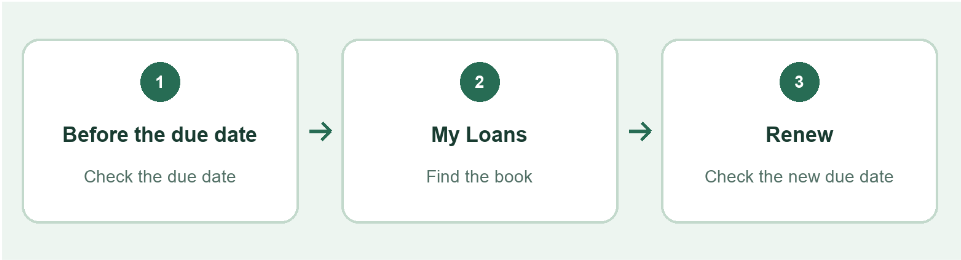

{'type': 'text', 'text': 'Figure 1. Renewal steps', 'page_idx': 1}

{'type': 'text', 'text': 'Confirm the result', 'page_idx': 1}

{'type': 'text',
 'text': 'After renewal, My Loans shows the new due date.',
 'page_idx': 1}

{'type': 'text',
 'text': 'Before returning the book, check the date again.',
 'page_idx': 1}

{'type': 'text', 'text': 'Library Borrowing Guide', 'page_idx': 1}

{'type': 'text', 'text': '2 / 2', 'page_idx': 1}

In [4]:
content_list, doc_id = await rag.parse_document(str(pdf_path), allow_ocr=False)

print(f"doc_id = {doc_id}")
display(dict(Counter(block["type"] for block in content_list)))

for block in content_list:
    display(block)
    if block["type"] == "image":
        display(Image(filename=block["img_path"], width=520))

### 4.1 Understand one parsed block before reading the full list

A parsed text block has this shape. The sentence below illustrates the renewal rule; inspect the output above for the exact parsed wording.

```json
{
  "type": "text",
  "text": "If nobody else has reserved the book, you may renew it once for 7 extra days.",
  "page_idx": 1
}
```

`page_idx=1` means page **2**, because page indices start at zero. A table block stores cell structure in `table_body`; an image block's `img_path` points to an extracted PNG.

The 21 text blocks also include headings, captions, and page numbers. The count does not mean there are 21 complete rules.


**Pause and predict — Check 1: Do we already have 23 chunks and 23 vectors?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

**Not yet.** We have 23 parsed blocks representing the PDF's content and layout. Ingestion will join and split the ordinary text, then process the table and image. This run ultimately produces 6 chunks.

If you answered “yes,” you are mixing up **parsed layout elements** and **retrieval units**. Follow the same evidence from section 4 into section 5.

</details>

## 5. Ingest: Unpack the work behind one function call

**Question for this step: How does parsed content become material we can search later?** `insert_content_list` looks like one call, but it coordinates all of the work below.

```mermaid
flowchart TD
    INPUT["23 parsed blocks"] --> T["21 text blocks"]
    INPUT --> TABLE["1 table"]
    INPUT --> IMAGE["1 image"]
    T --> JOIN["Join ordinary text: 180 tokens"]
    JOIN --> SPLIT["Window: 75 tokens; overlap: 20 tokens"]
    SPLIT --> FOUR["4 text chunks"]
    TABLE --> LLM["Text model analyzes table structure and nearby text"]
    LLM --> TC["Table chunk: 1941 tokens"]
    IMAGE --> VLM["Vision model describes the image"]
    VLM --> IC["Image chunk: 430 tokens"]
    FOUR --> STORE["Store 6 chunks and their provenance"]
    TC --> STORE
    IC --> STORE
```

Table analysis receives table structure and nearby text. Image analysis receives the image and related text. Their generated descriptions also enter the text-based retrieval system. Calling this entire stage “embedding” would hide these separate tasks.

**First, understand the text windows.** The joined ordinary text contains 180 tokens in this run. A 75-token window with a 20-token overlap advances by 55 tokens each time.

| Text chunk | Token range | Length | Overlap with previous chunk |
| --- | --- | ---: | --- |
| 1 | 1–75 | 75 | None |
| 2 | 56–130 | 75 | 56–75 |
| 3 | 111–180 | 70 | 111–130 |
| 4 | 166–180 | 15 | 166–180 |

The final chunk has only 15 tokens and is entirely contained in the end of chunk 3. This last pair therefore shares 15 tokens; 20 is the configured overlap for full windows.

Overlap repeats text near a boundary in adjacent chunks, reducing the chance that a split loses important context. Compare the end of one text chunk with the beginning of the next. Token windows do not guarantee complete sentences, and a chunk can cross a page boundary.

**After running, check the status only:** `fully_processed` should be `True`; this saved run has `chunks_count=6`. A successful `insert_content_list` call returns `None`. The subsequent `status` record tells us whether processing finished.


**Pause and predict — Check 2: Does the second text chunk start at token 56 or 76? Why can the table chunk exceed 75 tokens?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

It starts at **56**, because the stride is `75 - 20 = 55`. The 75-token window applies to ordinary text. Tables and images use separate processing paths, so their chunks may be longer.

If you chose 76, revisit overlap. If you expected the table chunk to stay below 75 tokens, trace the three content branches in the diagram.

</details>

In [5]:
if not api_key:
    raise RuntimeError("Set OPENAI_API_KEY in src/.env, then run uv run --env-file src/.env jupyter lab from the project root.")

before_insert = len(calls)
await rag.insert_content_list(content_list, file_path=str(pdf_path), doc_id=doc_id)
status = await rag.get_document_processing_status(doc_id)
display(status)

if not status["fully_processed"]:
    raise RuntimeError("Document ingestion is incomplete. Check the document status and library logs above.")

INFO: Parser 'docling' installation verified


INFO: Initializing LightRAG with parameters: {'working_dir': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage', 'llm_model_name': 'gpt-6-luna', 'chunk_token_size': 75, 'chunk_overlap_token_size': 20, 'addon_params': {'language': 'English'}}


INFO: [] Created new empty graph file: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/graph_chunk_entity_relation.graphml


INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_entities.json'} 0 data


INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_relationships.json'} 0 data


INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_chunks.json'} 0 data


... (231 outputs left out)

INFO: Updated doc_status: added 2 multimodal chunks to standard chunks_list (total chunks: 6)


INFO: Multimodal content processing complete


INFO: Content list insertion complete for: /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf


{'exists': True,
 'text_processed': True,
 'multimodal_processed': True,
 'fully_processed': True,
 'chunks_count': 6,
 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9',
  'chunk-f74d3981177947bc583a0860d03ffe3f',
  'chunk-b5b66dc4cdc65aee472efcef7cbf0db9',
  'chunk-0bec09cbf50b78e30405fdc3229058fb',
  'chunk-cf352990e5eade4fe4af96431997ef38',
  'chunk-816ab159240b772497183b1cde78b387'],
 'status': <DocStatus.PROCESSED: 'processed'>,
 'updated_at': '2026-11-16T06:29:44+00:00',
 'raw_status': {'status': <DocStatus.PROCESSED: 'processed'>,
  'chunks_count': 6,
  'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9',
   'chunk-f74d3981177947bc583a0860d03ffe3f',
   'chunk-b5b66dc4cdc65aee472efcef7cbf0db9',
   'chunk-0bec09cbf50b78e30405fdc3229058fb',
   'chunk-cf352990e5eade4fe4af96431997ef38',
   'chunk-816ab159240b772497183b1cde78b387'],
  'content_summary': 'Library Borrowing Guide\n\nBorrowing and returning books\n\nBefore borrowing, check that your account is eligible.\n\nT

### 5.1 Distinguish interpreting content from encoding content

The next cell inspects model calls added during ingestion. **Look for just two kinds of output:**

- An image or table description is readable text, such as an explanation of the renewal diagram.
- An embedding result is a `shape` and a numeric sample. For example, `(N, 1536)` means N vectors, each with 1536 dimensions.

In this example, the table chunk explains the 3-book limit and 14-day loan period. The image chunk describes the renewal steps. Descriptions may incorporate nearby text, so return to the PDF when checking a fact.

If this run reused an already processed document or cached results, there may be fewer new calls, or no sample for a particular task. An empty `calls` list alone does not show that ingestion failed; also inspect the completion status.


**Pause and predict — Check 3: Who extracts entities and relationships from “renewal adds 7 days,” and who turns text into numbers?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

The text model extracts entities and relationships. The embedding model encodes the supplied text as vectors. The vision model interprets images.

If you thought one embedding call did everything, return to section 2 and separate **interpretation and generation by an LLM/VLM** from **encoding by an embedding model**.

</details>

{'embed': 120, 'llm': 13, 'vision': 1}

{'kind': 'llm',
 'model': 'gpt-6-luna',
 'prompt': 'Please analyze this table content considering the surrounding context, and provide a JSON response with the following structure:\n\n{\n    "detailed_description": "A comprehensive analysis of the table including:\n    - Table structure and organization\n    - Column headers and their meanings\n    - Key data points and patterns\n    - Statistical insights and trends\n    - Relationships between data elements\n    - Significance of the data presented in relation to surrounding context\n    - How the table supports or illustrates concepts from the surrounding content\n    Always use specific names and values instead of general references.",\n    "entity_info": {\n        "entity_name": "descriptive name for this table",\n        "entity_type": "table",\n        "summary": "concise summary of the table\'s purpose, key findings, and relationship to surrounding content (max 100 words)"\n    }\n}\n\nContext from surrounding content:\nLibrar

{'kind': 'vision',
 'model': 'gpt-6-luna',
 'messages': [{'role': 'system',
   'content': 'You are an expert image analyst. Provide detailed, accurate descriptions.'},
  {'role': 'user',
   'content': [{'type': 'text',
     'text': 'Please analyze this image in detail, considering the surrounding context. Provide a JSON response with the following structure:\n\n{\n    "detailed_description": "A comprehensive and detailed visual description of the image following these guidelines:\n    - Describe the overall composition, layout, and structure\n    - Transcribe ALL text labels verbatim (titles, annotations, axis labels, node names, edge labels, legends, etc.)\n    - For diagrams/charts/flowcharts/UML: enumerate every node, edge, relationship type, and connection direction; preserve structural topology\n    - For photographs/illustrations: identify all objects, people, text, and visual elements; describe actions and scene\n    - Explain relationships and connections between elements and h

{'kind': 'embed',
 'model': 'text-embedding-3-small',
 'texts': ['Library Borrowing Guide\n\nBorrowing and returning books\n\nBefore borrowing, check that your account is eligible.\n\nThe table lists the limit and standard loan period.\n\nCheck the due date\n\nAfter borrowing, My Loans shows the due date for each book.\n\nIf you borrow several books, check each title separately.\n\nReturn each book on or before its due date.\n\nLibrary Borrowing Guide',
  'check each title separately.\n\nReturn each book on or before its due date.\n\nLibrary Borrowing Guide\n\n1 / 2\n\nHow to Renew\n\nIf you need more time, request a renewal before the due date.\n\nOpen My Loans, find the book, and click "Renew".\n\nIf nobody else has reserved it, renew once for 7 extra days.\n\nIf it is reserved',
  '".\n\nIf nobody else has reserved it, renew once for 7 extra days.\n\nIf it is reserved, return it by the original due date.\n\nFigure 1. Renewal steps\n\nConfirm the result\n\nAfter renewal, My Loans sho

In [ ]:
from raganything.prompt import PROMPTS

index_calls = calls[before_insert:]
display(dict(Counter(call["kind"] for call in index_calls)))

description_prompts = {PROMPTS["TABLE_ANALYSIS_SYSTEM"], PROMPTS["EQUATION_ANALYSIS_SYSTEM"]}
for call in index_calls:
    if call["kind"] == "vision" or call.get("system_prompt") in description_prompts:
        display(call)

embedding_sample = next((call for call in index_calls if call["kind"] == "embed"), None)
if embedding_sample:
    display(embedding_sample)

## 6. Open what the system saved

**Step 5 saved the information. Step 6 reads it back.** This step does not ask a question or write an answer.

We will follow one sentence from the PDF:

> If nobody else has reserved it, renew once for 7 extra days.

Here, **renew** means asking to keep the book longer. The sentence gives both a condition and a time limit. We want the system to keep that information so it can answer a question later.

### First: the chunk is still readable text

A **chunk** is a saved piece of text. Our sentence is part of a chunk. Making a vector does not remove the text.

Each chunk also has an **ID**. An ID is a label used to find that particular chunk. The label itself is not a summary of the text.

Here is a simplified view of one real saved chunk. The ID and text are shortened for reading:

```text
ID:   chunk-f74d3981…
Text: … Open My Loans, find the book, and click "Renew".
      If nobody else has reserved it, renew once for 7 extra days. …
```

### Second: the vector is a list of numbers used for matching

The embedding model takes the chunk's text and produces numbers. That list is its **vector**, also called an **embedding**.

Later, the system can use these numbers to find text related to a question. For example, “Can I keep the book longer?” may match the renewal text, even though the words differ. This is an illustration, not an extra query run by this cell.

```mermaid
flowchart TD
    ID["A chunk ID links two saved records"] --> T["Text: words a person or answer model can read"]
    ID --> V["Vector: numbers used to find related content"]
```

**Focus on what the numbers are for. You do not need to read meaning from each number.** The answering model will later read the selected text, not the vector's numbers.

### How to read the next output

The next code cell reads all six chunks. It also shows vectors for the first three chunk IDs.

| If you see this | Read it as |
| --- | --- |
| `Chunk ID` | The label for this saved piece of text |
| A paragraph under that label | The text is still available to read |
| `dimensions: 1536` | This vector contains 1536 numbers |
| `sample: [...]` | Only the first six numbers are shown |

**Your task:** Find the sentence about “7 extra days.” Then find the vector record with the same chunk ID. Seeing the same ID is enough; leave the individual numbers aside.

<details>
<summary>Optional: where is this chunk in the PDF?</summary>

This saved chunk spans pages 1–2. Its fields are `page_idx=0` and `page_idx_end=1`, because page indices start at zero. The renewal sentence itself is on PDF page 2. We will follow these source details in section 7.1.

</details>

<details>
<summary>Optional: why can stored numbers differ slightly from the original numbers?</summary>

The vector store compresses numbers using a format called float16. Small rounding differences are expected. You only need to check the chunk ID and the vector length here.

</details>


**Check 4: When writing the final answer, should the answer model read the selected text or the vector numbers?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

It reads the **selected text**. The vector helps find that text.

If you chose the numbers, return to the two boxes above. They have different jobs: one helps search; the other supplies readable information.

</details>

In [7]:
chunk_ids = status["chunks_list"]
chunks = await rag.lightrag.text_chunks.get_by_ids(chunk_ids)

for chunk_id, chunk in zip(chunk_ids, chunks):
    print(f"Chunk ID: {chunk_id}")
    if chunk is not None:
        display({key: value for key, value in chunk.items() if key != "content"})
        print(chunk["content"], end="\n\n")

vectors_by_id = await rag.lightrag.chunks_vdb.get_vectors_by_ids(chunk_ids[:3])
display({
    chunk_id: {"dimensions": len(vector), "sample": vector[:6]}
    for chunk_id, vector in vectors_by_id.items()
})

Chunk ID: chunk-9afabfd0277eadab270f8c9f0d4f67b9


{'tokens': 75,
 'chunk_order_index': 0,
 'full_doc_id': 'doc-501ac0a4b56d2d98331eb3d9164f0dfd',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:3eeced7c11464dfad23f1b24fe6334ef',
  'default:extract:bb001d241e3978b89e7505580c667dac'],
 'create_time': 1794810480,
 'update_time': 1794810522,
 '_id': 'chunk-9afabfd0277eadab270f8c9f0d4f67b9',
 'page_idx': 0}

Library Borrowing Guide

Borrowing and returning books

Before borrowing, check that your account is eligible.

The table lists the limit and standard loan period.

Check the due date

After borrowing, My Loans shows the due date for each book.

If you borrow several books, check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

Chunk ID: chunk-f74d3981177947bc583a0860d03ffe3f


{'tokens': 75,
 'chunk_order_index': 1,
 'full_doc_id': 'doc-501ac0a4b56d2d98331eb3d9164f0dfd',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:9738f06dd6575e508a8646784deab196',
  'default:extract:87893769f415486e238d615bf7997603'],
 'create_time': 1794810480,
 'update_time': 1794810522,
 '_id': 'chunk-f74d3981177947bc583a0860d03ffe3f',
 'page_idx': 0,
 'page_idx_end': 1}

check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved

Chunk ID: chunk-b5b66dc4cdc65aee472efcef7cbf0db9


{'tokens': 70,
 'chunk_order_index': 2,
 'full_doc_id': 'doc-501ac0a4b56d2d98331eb3d9164f0dfd',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:ced8271e82c8595e0bb95ea3167563d1',
  'default:extract:1d596e8bb38ffb6a0a28364e9000e296'],
 'create_time': 1794810480,
 'update_time': 1794810522,
 '_id': 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9',
 'page_idx': 1}

... (4 outputs left out)

Table Analysis:
Image Path: 
Caption: None
Structure: {'table_cells': [{'bbox': {'l': 73.0, 't': 258.9420462500001, 'r': 98.70190375, 'b': 270.4763068775368, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 0, 'end_col_offset_idx': 1, 'text': 'Item', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 347.0, 't': 258.9420462500001, 'r': 419.9186974999999, 'b': 270.4763068775368, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 1, 'end_col_offset_idx': 2, 'text': 'Student rule', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 73.0, 't': 305.9359425, 'r': 215.40722000000005, 'b': 317.4780712747022, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 1, 'end_row_offset_idx': 2, 'start_col_off

{'tokens': 430,
 'full_doc_id': 'doc-501ac0a4b56d2d98331eb3d9164f0dfd',
 'chunk_order_index': 5,
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:16e0a5718bc1f3593cee9902885fd49a',
  'default:extract:01aa497bb58b1c8adfbba0d4efb0a8d3'],
 'is_multimodal': True,
 'modal_entity_name': 'Three-Step Library Book Renewal Process (image)',
 'original_type': 'image',
 'page_idx': 1,
 'create_time': 1794810528,
 'update_time': 1794810553,
 '_id': 'chunk-816ab159240b772497183b1cde78b387'}


Image Content Analysis:
- Section Path: None
- Neighbor Text: Open My Loans, find the book, and click "Renew". If nobody else has reserved it, renew once for 7 extra days. If it is reserved, return it by the original due date. Figure 1. Renewal steps Confirm the result After renewal, My Loans shows the new due date.
Image Path: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png
Captions: Figure 1. Renewal steps
Footnotes: None

Visual Analysis: A horizontal, three-step renewal diagram on a pale green background. Three white rounded-rectangle cards with thin light-green outlines are arranged from left to right, with dark-green right-pointing arrows between consecutive cards to show the sequence.

1. The first card has a dark-green circular badge containing “1”. Beneath it, the bold heading reads “Before the due date”, followed by the smaller text “Check the due date”.
2. The middle card has a dark-gr

{'chunk-9afabfd0277eadab270f8c9f0d4f67b9': {'dimensions': 1536,
  'sample': [-0.026214599609375,
   0.045989990234375,
   0.0384521484375,
   -0.009552001953125,
   0.00289154052734375,
   -0.0240631103515625]},
 'chunk-f74d3981177947bc583a0860d03ffe3f': {'dimensions': 1536,
  'sample': [-0.03424072265625,
   0.053375244140625,
   0.0274200439453125,
   -0.0303802490234375,
   -0.008056640625,
   -0.0204620361328125]},
 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9': {'dimensions': 1536,
  'sample': [-0.0231781005859375,
   0.0789794921875,
   0.026458740234375,
   -0.0110015869140625,
   -0.0018787384033203125,
   0.00618743896484375]}}

### 6.1 A graph connects facts

Now look at the third kind of saved information: the **knowledge graph**.

The text model can identify things mentioned in a passage and describe how they are connected. For example:

```mermaid
flowchart LR
    R["Renewal"] ---|"extends the loan by"| D["7 days"]
```

This is a simplified example, not a complete rule. The original sentence also says that nobody else may have reserved the book.

- An **entity** is a thing or concept, such as renewal or a loan period. It is a **node** in the graph.
- A **relationship** describes a connection between entities. It is an **edge** in the graph.
- A **graph** is a collection of these nodes and connections.

The graph saves `source_id` too. This field contains the label of the chunk that supports a fact. It lets us go back and read the full rule, including its conditions.

```text
A connection about renewal
→ source_id
→ the supporting chunk
→ read the original conditions
```

So far, we have three different jobs:

| Saved item | Job |
| --- | --- |
| Chunk text | Keep the readable information |
| Vector | Help find related information |
| Graph | Keep connections between things mentioned in the material |

The connections show meaning. They do not automatically show the order of paragraphs and pictures in the PDF.


**Check 5: A graph connection says that renewal adds seven days. Which field helps you find the text supporting that connection?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

Use **`source_id`**. It points to one or more supporting chunks.

Read the chunk to check the full rule. A short graph description may not show every condition. If you chose the vector's numbers, remember that numbers help with matching; source IDs help find the supporting text.

</details>

### 6.2 Optional: the graph also has vectors

You can come back to this after the basic three jobs above make sense.

<details>
<summary>Explain chunk vectors, entity vectors, and relationship vectors</summary>

All three are lists of numbers made from text. What changes is the text being encoded.

| Vector type | Text sent to the embedding model | What it helps find |
| --- | --- | --- |
| Chunk vector | A passage containing the renewal rule | A relevant passage |
| Entity vector | An entity's name and description, such as “renewal” and what it means | A relevant thing or concept |
| Relationship vector | The names of two entities and a description of their connection | A relevant connection or rule |

These are simple examples. Ordinary relationship inputs also include keywords; some image or table entities use a short description directly. The next code cell shows a graph preview, not all the entity and relationship vectors.

The same embedding model can make all three types. A relationship vector is made from the relationship's description; it is not calculated by subtracting two entity vectors.

Our six chunks have six chunk vectors. The entity and relationship vectors are additional records. One chunk can mention several entities, and the same entity can appear in several chunks.

**Try classifying these:** a full renewal passage; a description of “renewal”; a description of how renewal changes the loan period.

They produce a chunk vector, an entity vector, and a relationship vector, respectively. The difference is the information being encoded, not three different models.

</details>

**For the next code cell, do just one thing:** expand the output, find a `source_id`, and look for that chunk ID in the earlier chunk output. This connects the graph back to readable text.

<details>
<summary>Optional: what do the graph preview numbers mean?</summary>

`nodes` are the entities shown; `edges` are their connections. This preview asks for at most 30 nodes. `is_truncated=True` means some of the full graph has been left out of the preview. It is not an error.

</details>

In [8]:
graph = await rag.lightrag.get_knowledge_graph("*", max_nodes=30)
print(f"Nodes: {len(graph.nodes)}, edges: {len(graph.edges)}, truncated: {graph.is_truncated}")
display(graph.model_dump())

INFO: [] Subgraph query successful | Node count: 28 | Edge count: 67


Nodes: 28, edges: 67, truncated: False


{'nodes': [{'id': 'Library Borrowing Guide',
   'labels': ['Library Borrowing Guide'],
   'properties': {'entity_id': 'Library Borrowing Guide',
    'entity_type': 'content',
    'description': 'Library Borrowing Guide is the title of a guide about library borrowing.<SEP>The Library Borrowing Guide provides instructions for checking titles, returning books by their due dates, and requesting renewals.<SEP>The Library Borrowing Guide provides instructions for borrowing and returning books.<SEP>The Library Borrowing Guide provides instructions for renewing and returning a book.<SEP>The Library Borrowing Guide provides baseline student borrowing limits and instructions for checking eligibility, tracking due dates, renewing books, and returning them on time.',
    'source_id': 'chunk-9afabfd0277eadab270f8c9f0d4f67b9<SEP>chunk-b5b66dc4cdc65aee472efcef7cbf0db9<SEP>chunk-f74d3981177947bc583a0860d03ffe3f<SEP>chunk-0bec09cbf50b78e30405fdc3229058fb<SEP>chunk-cf352990e5eade4fe4af96431997ef38',
   

### 6.3 Why keep a graph as well as vectors?

**A graph is an extra way to find related information. It is not required for every RAG application.** For this two-page guide, ordinary text retrieval, or giving the whole guide to a model, could be enough. We use a graph here to learn how this system works.

| Search method | A plain-English question it helps answer |
| --- | --- |
| Vector search | Which passages have a similar meaning to my question? |
| Graph search | Which things and facts are connected to the subjects in my question? |

For example, our saved graph contains these connections. The edge labels below are shortened for readability:

```mermaid
flowchart LR
    M["My Loans"] ---|"Where borrowers find their books"| B["Book"]
    B ---|"Can be renewed once for 7 extra days<br/>if nobody has reserved it"| R["Renewal"]
```

Imagine that one passage explains where to find a book, while another explains when it can be renewed. The shared **Book** node helps connect those facts. Later, retrieval can use the connections to collect related evidence.

The graph does not replace the source text. A short relationship description may leave out a condition. The answer still needs supporting passages, such as the rule about another person's reservation.

**Keep these jobs separate:** the LLM writes descriptions and extracts facts; Python code saves and merges graph records; the embedding model turns text into numbers for searching. Embedding does not invent the graph's connections.


### 6.4 Can the graph include the table and image? What does each model receive?

**Yes. The graph can connect information from body text, a table, and an image.** But there are two different model tasks: first **interpret the table or image**, then **extract graph facts from a textual representation**.

| Material | What the earlier analysis receives | What graph extraction later receives |
| --- | --- | --- |
| Body text | No separate table/image analysis | One text chunk |
| Table | Structured table cells, captions or footnotes if present, and surrounding text | Table structure and metadata, plus the generated analysis |
| Image | Actual image pixels, caption if present, and surrounding text | A textual representation containing the visual description, image path, caption, and contextual information |

```mermaid
flowchart TD
    T["Body text"] --> TC["Text chunks"]
    TB["Table cells + surrounding text"] --> TA["LLM table analysis"]
    TA --> TBC["Table structure + analysis"]
    I["Image pixels + surrounding text"] --> IA["Vision-model analysis"]
    IA --> IC["Image description + context"]
    TC --> E["Extract nodes and edges<br/>One chunk per extraction request"]
    TBC --> E
    IC --> E
    E --> G["Merge matching entities and relationships<br/>Save graph and source links"]
```

In this installed version, **all six chunks are processed, but they are not all sent together in one extraction request**. Each request includes one chunk plus the extraction instructions and examples. The image pixels go to the earlier vision-analysis call; the later graph-extraction call receives text.

**Why did the table and image analyses mention facts from nearby paragraphs?** The default context setting includes text from the current page and one page on either side, subject to a 2,000-token limit. Our guide has only two short pages, so text from both pages can be included. The default context filter includes text, not the nearby table or image pixels themselves.

The framework also creates a node for each table or image and adds connections named **`belongs_to`**. Read that as: “This entity was extracted while processing this table or image.” It is an association with the processed object, not proof that every fact was literally printed inside that object.

For example, the table cells contain **3 books** and **14 days**. Renewal information in the table analysis can come from the surrounding text. We should check the source before saying “the table itself states the renewal rule.”

The graph represents meaning and associations. It is not automatically a reading-order chain such as `text 1 → image 1 → text 2`.


### 6.5 Read the prompt and one complete extraction response

**One request can return many nodes and edges together.** The model writes structured text; Python reads the records and saves them in the graph. There is no separate model request for every node or edge.

Here are selected, verbatim instructions from the installed LightRAG system prompt. Other formatting rules and worked examples have been omitted:

```text
You are a Knowledge Graph Specialist responsible for extracting entities and relationships from the input text.

Identify clearly defined and meaningful entities in the input text.

Identify direct, clearly stated, and meaningful relationships between previously extracted entities.
```

The system prompt also asks for entity descriptions based solely on the input text, consistent entity names, and English output in our configuration. Its record formats, with the separator filled in, are:

```text
entity<|#|>entity_name<|#|>entity_type<|#|>entity_description
relation<|#|>source_entity<|#|>target_entity<|#|>relationship_keywords<|#|>relationship_description
```

The user prompt begins with this instruction:

```text
---Task---
Extract entities and relationships from the input text in Data to be Processed below.
```

After additional output instructions and the allowed entity types, its `<Input Text>` section contains **one chunk**. Part of our example chunk says:

```text
Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.
```

Two actual lines returned for this chunk are:

```text
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
```

Read the first line as **“make a node named My Loans, give it a category, and describe it.”** Read the second as **“connect My Loans to Book and explain why.”** `Content` is the category chosen by the model here; it is not another node.

`<|#|>` separates fields. `<|COMPLETE|>` marks the end of the response. Neither marker is a node.

**The complete first response contains 6 entity records and 7 relationship records, all from one model call.** The entity names are Library Borrowing Guide, Book, Due Date, My Loans, Renewal, and Reservation.

<details>
<summary>Show the complete 75-token input chunk, exactly as saved</summary>

Chunk ID: `chunk-f74d3981177947bc583a0860d03ffe3f`

```text
check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved
```

The footer fragments and unfinished last sentence are really in this chunk. Token-based splitting does not always stop at sentence boundaries. This is one reason to keep overlap and check the original evidence rather than trusting an extracted statement without checking it.

</details>

<details>
<summary>Show the complete raw first response: 6 nodes and 7 edges</summary>

This is the saved first-pass response for the chunk above. No lines have been removed or rewritten.

```text
entity<|#|>Library Borrowing Guide<|#|>Content<|#|>The Library Borrowing Guide provides instructions for checking titles, returning books by their due dates, and requesting renewals.
entity<|#|>Book<|#|>Artifact<|#|>A book is an item that can be borrowed, returned by its due date, and renewed if eligible.
entity<|#|>Due Date<|#|>Concept<|#|>The due date is the deadline by which a borrowed book should be returned and before which a renewal should be requested.
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
entity<|#|>Renewal<|#|>Concept<|#|>A renewal gives a borrower more time to keep a book; it can be requested once for seven extra days if nobody else has reserved the book.
entity<|#|>Reservation<|#|>Concept<|#|>A reservation by another person makes a book ineligible for the renewal described in the guide.
relation<|#|>Library Borrowing Guide<|#|>Book<|#|>borrowing instructions, returns<|#|>The Library Borrowing Guide instructs borrowers to return each book on or before its due date.
relation<|#|>Library Borrowing Guide<|#|>Renewal<|#|>renewal instructions<|#|>The Library Borrowing Guide explains how to request a renewal and the conditions for receiving one.
relation<|#|>Book<|#|>Due Date<|#|>return deadline<|#|>A borrowed book should be returned on or before its due date.
relation<|#|>Renewal<|#|>Due Date<|#|>renewal deadline<|#|>A renewal should be requested before the book's due date.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
relation<|#|>Book<|#|>Renewal<|#|>renewal eligibility<|#|>A book can be renewed once for seven extra days if nobody else has reserved it.
relation<|#|>Reservation<|#|>Renewal<|#|>renewal restriction<|#|>A book cannot receive the described renewal if someone else has reserved it.
<|COMPLETE|>
```

The first six lines describe entities. The next seven describe relationships. The final marker ends the response. These records are the model's extraction, not a guarantee that every interpretation is correct.

</details>

The default workflow then makes a separate **review pass**, also called *gleaning*. Its prompt begins:

```text
Based on the last extraction task, identify and extract any **missed or incorrectly formatted** entities and relationships from the input text.
```

That review receives the original request and response as conversation history. For this particular chunk it returned 2 additional entity records and 4 relationship records. Do not confuse that second response with the complete first response shown above.

These examples are snapshots of the saved English run; reading them makes no API calls. You can inspect the full templates in [the installed prompt file](../.venv/lib/python3.14/site-packages/lightrag/prompt.py) and the saved requests and responses in [the local cache](../outputs/library_rag_storage/kv_store_llm_response_cache.json). In an extraction cache record, `original_prompt` stores the user prompt, system prompt, and serialized history together; `return` stores the model's response.


### 6.6 How do separately processed chunks become one connected graph?

**The model does not need to see every chunk together. Python combines the extraction results by matching entity names.** The chunks keep their own IDs and text; their facts can share nodes in one graph.

Imagine two people making index cards independently. Both write a card titled **Book**. When we file the cards, we put both descriptions under the same **Book** heading. That shared heading connects their information.

Here is what happens with real records from our saved run:

| Extraction result | Entity name | Relationship endpoints |
| --- | --- | --- |
| Text chunk, first pass | `Book`, `Renewal` | `Book` and `Renewal` |
| Table chunk, extraction plus review | `Book`, `Renewal` | `Book` and `Renewal` |

The table's Book–Renewal relationship appears in its **review pass**, rather than its first response. Its renewal information can come from the surrounding text included during analysis.

```mermaid
flowchart TD
    A["Text-chunk result<br/>Book, Renewal, and their relationship"] --> M["Python merge<br/>Match entity names and endpoint pairs"]
    B["Table-chunk extraction + review<br/>Book, Renewal, and their relationship"] --> M
    M --> BOOK["One shared Book node"]
    M --> RENEWAL["One shared Renewal node"]
    BOOK ---|"One combined relationship"| RENEWAL
    M --> E["Keep supporting chunk IDs<br/>Text evidence + table-analysis evidence"]
```

The merge works like this:

1. **Match nodes by name.** After basic text cleanup, `Book` matches an existing `Book` node. Add the new description and source information to that node.
2. **Match edges by their two endpoints.** In this workflow, `Book — Renewal` and `Renewal — Book` identify the same pair. Combine the relationship information instead of creating another copy of the pair.
3. **Keep evidence links.** The combined node or edge records the supporting chunk IDs in `source_id`. This lets retrieval return to the separate chunks later.

An edge with a new endpoint can extend the same graph. For example, a `Book — Due Date` relationship and a `Book — Renewal` relationship share **Book** even though they describe different facts. The chunks themselves do not need a direct `chunk A → chunk B` edge.

**The saved Book–Renewal edge has four supporting chunks:** two body-text chunks, the table-analysis chunk, and the image-analysis chunk.

<details>
<summary>Show the actual source IDs and the two extracted descriptions</summary>

Text-chunk first-pass relationship description:

```text
A book can be renewed once for seven extra days if nobody else has reserved it.
```

Table-chunk review relationship description:

```text
A borrowed book may be renewed once for seven extra days if the stated conditions are met.
```

The final edge's `source_id` includes these IDs; the list below adds labels for readability:

```text
Body text:      chunk-b5b66dc4cdc65aee472efcef7cbf0db9
Body text:      chunk-f74d3981177947bc583a0860d03ffe3f
Table analysis: chunk-cf352990e5eade4fe4af96431997ef38
Image analysis: chunk-816ab159240b772497183b1cde78b387
```

The saved field joins IDs with `<SEP>`. The graph also keeps merged descriptions. Long descriptions can trigger an additional summarization call, but matching these entity names does not require sending every original chunk to one model call.

</details>

**A limitation to remember:** this merge is based on matching names, not automatic understanding of every synonym. If one extraction says `Book` and another says `Volume`, they are not guaranteed to become the same node. The prompt asks for consistent naming, but the model can still use different names. Conversely, identical names can be ambiguous. Vector similarity is not the rule used to merge these nodes.

**Try it:** chunk A returns `Book — Due Date`; chunk B returns `Book — Renewal`. How many distinct entity names are there, and which name connects the facts?

<details>
<summary>Show the explanation</summary>

There are three: **Book**, **Due Date**, and **Renewal**. **Book** is shared. The two edges meet at that node. Each edge can still point back to its own supporting chunk.

This is a small teaching example, not a claim that the whole saved graph contains only three nodes.

</details>


#### 6.6.1 Follow each node and edge back to its own evidence

Your understanding is right: **each chunk's request can return several nodes and edges.** Each extraction works with its own chunk, without seeing other chunks' extraction results. Python then combines those results using shared entity names and relationship endpoint pairs.

Let's use your example. This is a small teaching example, not a literal copy of the saved graph. `chunk-1` and `chunk-2` are short labels that make the links easier to follow.

| Independent extraction | Result |
| --- | --- |
| Chunk 1 discusses renewal | `Book — Renewal` |
| Chunk 2 discusses borrowing rules | `Book — Borrow Rule` |

Python finds the same name, **Book**, and merges the two Book records. Both different relationships remain connected to that shared node:

```mermaid
flowchart LR
    BR["Borrow Rule"] ---|"Supported by chunk 2"| B["Book"]
    B ---|"Supported by chunk 1"| R["Renewal"]
```

If both chunks instead describe the same endpoint pair, such as `Book — Renewal`, Python combines that relationship's information and source links too. Different names such as `Book` and `Volume` are not guaranteed to merge.

**What is `source_id` for? It answers: “Which chunk supplied the evidence for this node or relationship?”** Python knows which chunk produced each extraction result, so it attaches that chunk's ID to the records. When records are merged, it keeps their supporting source IDs.

There is not just one source label for the entire graph. **Each node and each edge has its own evidence links:**

| Saved graph item | Its own `source_id` points to | Why? |
| --- | --- | --- |
| **Book** node | Chunk 1 and chunk 2 | Both extractions identify Book |
| **Renewal** node | Chunk 1 | This extraction identifies Renewal |
| **Borrow Rule** node | Chunk 2 | This extraction identifies Borrow Rule |
| **Book — Renewal** edge | Chunk 1 | This chunk supports the renewal relationship |
| **Book — Borrow Rule** edge | Chunk 2 | This chunk supports the borrowing-rule relationship |

**Sharing a node does not make every source support every connected edge.** Book has evidence from both chunks, but the Book–Renewal edge in this example still points only to chunk 1.

<details>
<summary>Show what the source_id field can look like</summary>

Using our short teaching IDs:

```text
Book node:                 source_id = "chunk-1<SEP>chunk-2"
Renewal node:              source_id = "chunk-1"
Borrow Rule node:          source_id = "chunk-2"
Book — Renewal edge:       source_id = "chunk-1"
Book — Borrow Rule edge:   source_id = "chunk-2"
```

The actual saved IDs are longer, for example `chunk-f74d3981177947bc583a0860d03ffe3f`. `<SEP>` separates multiple IDs stored in the field. A source ID is a lookup label; it does not contain the original sentence itself.

</details>

During retrieval, the program can follow a relationship back to readable evidence:

```mermaid
flowchart TD
    E["Find the Book - Renewal relationship"] --> S["Read this edge's source_id<br/>chunk-1 in our teaching example"]
    S --> C["Look up chunk-1 in the saved chunk store"]
    C --> T["Read the full rule<br/>Renew once for 7 extra days<br/>if nobody else has reserved the book"]
    C --> P["Use the chunk's document and page information<br/>to locate the source in the PDF"]
```

That full sentence matters: the short graph label **Renewal** does not explain the reservation condition. Source links let us retrieve and check it. For table/image-analysis chunks, this lookup returns the saved analysis representation; its provenance helps us check the underlying document. Analysis can include surrounding text, as section 6.4 explains.

**Try it:** Book has `source_id` links to chunks 1 and 2. Does that mean chunk 2 must contain the renewal rule?

<details>
<summary>Show the explanation</summary>

No. Book is mentioned in both chunks, but each relationship has its own source links. To check renewal, follow the **Book–Renewal edge's `source_id`**. In this example, that leads to chunk 1.

</details>

**Shared names connect the facts; `source_id` connects those facts back to their evidence.** The graph contains the facts successfully extracted, so it is not guaranteed to capture every fact in every chunk.


### 6.7 Does building this graph cost too many tokens for a small example?

**It adds substantial work for this tiny document.** A graph can be useful, but it is not automatically the cheapest or best choice for every task. Here, the extra machinery helps us learn.

The saved English run contains:

| Stored material | Count | Content tokens, before extraction instructions |
| --- | --- | --- |
| Body-text chunks | 4 | 235 total, including overlap |
| Table-analysis chunk | 1 | 1,941 |
| Image-analysis chunk | 1 | 430 |

The original joined body text has 180 tokens. Its overlapping chunks repeat some text, so their total is larger. The table representation is surprisingly long because it includes cell structures, coordinates, repeated cell data, and generated analysis. These counts describe stored chunk content, not the total API request or a bill.

The six chunks went through **6 initial extraction calls + 6 review calls**. There were also separate table and image analysis calls, embedding work, and later question-answering work. Even the short 15-token text chunk received extraction instructions and worked examples; review calls also included the earlier conversation.

However, **the number of graph edges is not the number of model calls**:

- One extraction response can contain many nodes and edges, as we saw in section 6.5.
- Python merges matching names and saves records locally.
- Our saved graph has **28 nodes and 67 edges**. **23 edges** are `belongs_to` associations added automatically, without a separate model call for each one.

<details>
<summary>Optional: a rough token estimate for the saved extraction requests</summary>

Counting the stored extraction request strings with the local `cl100k_base` tokenizer gives approximately **48,500 input tokens and 4,400 output tokens** across the 12 extraction responses.

This is a text-based estimate, **not measured billable usage**. The saved strings include serialized history; provider tokenization, message framing, and cached-input pricing can differ. The count excludes table/image interpretation, embeddings, and answering. The callbacks did not record the actual provider token-usage totals for this run.

The lesson is that repeated instructions, examples, and review history can dominate the size of a small source document.

</details>

Possible ways to reduce ingestion cost include using larger text chunks, reducing review passes, or passing a more compact table representation. Each changes what the model sees or checks, so it needs evaluation. None of those settings is changed by this explanation. Choosing a simpler retrieval mode later does not undo graph-building work already done during ingestion.

**Before Step 7, explain this path in your own words:**

```text
One chunk goes to the model.
One response describes several nodes and edges.
Python merges results that share entity names and endpoint pairs.
Source IDs preserve the links to the supporting chunks.
Step 7 searches the saved information to find evidence for a question.
```

**Quick check: Does a response containing 6 nodes and 7 edges require 13 extraction requests?**

<details>
<summary>Show the explanation</summary>

No. Our real example returned all 13 records in **one response to one extraction request**. A separate review request can add or correct records afterward. Saving a graph edge and making a model request are different operations.

</details>


## 7. Find text that can answer the question

**Retrieval means finding relevant saved information and bringing it back.** The system has already saved the chunks, vectors, and graph. Now it uses them.

The code asks our full question:

> How many books can a student borrow at a time, for how long, and how can they renew them?

The table can support “3 books, 14 days.” The renewal text can support “once for 7 extra days,” with its conditions. We call such supporting information **evidence**.

```mermaid
flowchart TD
    Q["Ask the question"] --> V["Use vectors to find related chunks"]
    Q --> G["Find related things and connections in the graph"]
    G --> T["Follow source IDs to supporting chunks"]
    V --> C["Collect the matching text"]
    T --> C
    C --> E["Remove repeated results and keep evidence that fits"]
```

`mix` means that this query uses both ways of finding information. This step returns evidence; it does not write the final answer yet.

**Read the next output in this order:**

1. Find `chunks`. Look for “3 books,” “14 days,” and “7 extra days.”
2. Find `references`. Check that the file is `library-guide.pdf`.

You can leave the long lists of entities and relationships for later. The important result is that the system has brought back text that can support an answer.

<details>
<summary>Optional: which parts use a model, and which run locally?</summary>

The text model picks useful words from the question, called **keywords**, unless those results are already cached. The embedding model turns the question and keywords into vectors.

The local program then compares vectors, looks up graph records, and removes repeated results. The vector comparison uses **cosine similarity**: a score for how closely two vectors match. You do not need its formula to follow this lesson.

The question vector finds chunks. Specific keywords find entities. Topic keywords find relationships. Graph records lead back to chunks through `source_id`. The inputs can be sent together in one embedding request. Extra reranking is disabled in this notebook.

</details>

In [9]:
question = "How many books can a student borrow at a time, for how long, and how can they renew them?"
print(question)

retrieval = await rag.lightrag.aquery_data(
    question, QueryParam(mode="mix", enable_rerank=False)
)

print(retrieval["status"], retrieval["message"])
print("Keywords")
display(retrieval.get("metadata", {}).get("keywords", {}))

for field in ("entities", "relationships", "chunks", "references"):
    print(field)
    display(retrieval["data"].get(field, []))

How many books can a student borrow at a time, for how long, and how can they renew them?


INFO:  == LLM cache == saving: mix:keywords:2545045a3a628a91045c61f7510377d8


INFO: Query nodes: Student borrowing limit, Books per student, Loan duration, Renewal process (top_k:40, cosine:0.2)


INFO: Local query: 28 entites, 67 relations


INFO: Query edges: Library borrowing policy, Loan period, Book renewal (top_k:40, cosine:0.2)


INFO: Global query: 22 entites, 40 relations


... (14 outputs left out)

chunks


[{'reference_id': '1',
  'content': 'check each title separately.\n\nReturn each book on or before its due date.\n\nLibrary Borrowing Guide\n\n1 / 2\n\nHow to Renew\n\nIf you need more time, request a renewal before the due date.\n\nOpen My Loans, find the book, and click "Renew".\n\nIf nobody else has reserved it, renew once for 7 extra days.\n\nIf it is reserved',
  'file_path': 'library-guide.pdf',
  'chunk_id': 'chunk-f74d3981177947bc583a0860d03ffe3f'},
 {'reference_id': '1',
  'content': "Table Analysis:\nImage Path: \nCaption: None\nStructure: {'table_cells': [{'bbox': {'l': 73.0, 't': 258.9420462500001, 'r': 98.70190375, 'b': 270.4763068775368, 'coord_origin': 'TOPLEFT'}, 'row_span': 1, 'col_span': 1, 'start_row_offset_idx': 0, 'end_row_offset_idx': 1, 'start_col_offset_idx': 0, 'end_col_offset_idx': 1, 'text': 'Item', 'column_header': True, 'row_header': False, 'row_section': False, 'fillable': False}, {'bbox': {'l': 347.0, 't': 258.9420462500001, 'r': 419.9186974999999, 'b': 2

references


[{'reference_id': '1', 'file_path': 'library-guide.pdf'}]

### 7.1 Check where the information came from

Suppose the system found “7 extra days.” We should be able to check that statement in the PDF.

```mermaid
flowchart LR
    G["Graph connection"] -->|"source_id"| C["Supporting chunk"]
    C --> T["Read the full renewal rule"]
    T --> P["Check the rule on PDF page 2"]
```

Here is how to read the labels:

| Label in the output | Plain meaning |
| --- | --- |
| `chunk_id` | Which piece of text is this? |
| `source_id` | Which pieces of text support this graph fact? |
| `page_idx` | Which PDF page does the chunk start on? |
| `reference_id` | Which source file does this result come from? |

For our renewal example, the chunk label starts with `chunk-f74d3981…`. Read it and find the condition about reservations. It spans pages 1–2 (`page_idx=0`, `page_idx_end=1`), and the renewal sentence is on page 2.

The answer's `[1]` points to the whole file, `library-guide.pdf`. It does not identify one particular sentence. To check a sentence, use the chunk and its page information as well.

**Small check:** Two chunks both have `reference_id="1"`. Are they the same text?

<details>
<summary>Show the explanation</summary>

No. They come from the same **file**, but can contain different text. A file label and a chunk label identify different things.

</details>

<details>
<summary>Optional: how much did this saved query find?</summary>

It returned 28 entities, 67 relationships, six evidence chunks, and one source file. The document is short, so all six chunks were selected. A larger collection does not mean the system will read every chunk; search settings and limits on input length restrict the results.

</details>

## 8. Give the answer model the question and supporting text

We now have relevant text. The next job is to put it together with the question and some instructions.

A **prompt** is the input sent to a model. Here it has two message types:

| Message | What it contains |
| --- | --- |
| `system` | Instructions for answering, plus the supporting information |
| `user` | The person's question |

```mermaid
flowchart LR
    I["Instructions"] --> S["system message"]
    T["Supporting text and source labels"] --> S
    Q["The question"] --> U["user message"]
    S --> M["Input the answer model will read"]
    U --> M
```

In this lesson, **context** means the information included to help the model answer. It includes the selected text, graph facts, and source labels. The vector numbers are not the reading material.

The next cell shows this context. **Find the loan limit and the renewal condition.** You do not have to read every line.

The preview calls below each search the saved index again. They do not simply reuse the `retrieval` variable from section 7.


**Check 6: If you can see a context or prompt preview, has the system already written the final answer?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

No. The preview shows the material prepared for answering. Section 9 makes the call that returns the answer, or reuses a saved answer.

If this was unclear, separate **preparing the reading material** from **asking the model to write an answer**.

</details>

<details>
<summary>Optional: why does the notebook call four similar query functions?</summary>

They let us observe different parts of the process:

| Call | What it returns |
| --- | --- |
| `aquery_data` | Results organized into fields such as chunks and references |
| `only_need_context=True` | Supporting information assembled as text |
| `only_need_prompt=True` | A preview of the prompt |
| Ordinary `aquery` | The answer |

Each call performs retrieval independently. The first three skip final answer generation, but can still call the keyword and embedding models. A normal application can use the last call alone to obtain an answer.

</details>

In [10]:
context = await rag.aquery(
    question, mode="mix", only_need_context=True, vlm_enhanced=False, enable_rerank=False,
)
print(context)

INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...


INFO: Query mode: mix


INFO: Query nodes: Student borrowing limit, Books per student, Loan duration, Renewal process (top_k:40, cosine:0.2)


INFO: Local query: 28 entites, 67 relations


INFO: Query edges: Library borrowing policy, Loan period, Book renewal (top_k:40, cosine:0.2)


INFO: Global query: 22 entites, 40 relations


... (6 outputs left out)

INFO: Final context: 28 entities, 67 relations, 6 chunks


INFO: Final chunks S+F/O: E8/1 E14/2 E11/3 E10/4 E11/5 E1/6


INFO: Text query completed



Knowledge Graph Data (Entity):

```json
{"entity": "Student Book Borrowing Limits and Standard Loan Period (table)", "type": "table", "description": "The table states that students may borrow a maximum of 3 books at a time, with a standard loan period of 14 days. It supplies the baseline rules for the Library Borrowing Guide; surrounding instructions explain checking individual due dates in My Loans and the conditional option to renew once for 7 extra days."}
{"entity": "Book", "type": "artifact", "description": "A book is an item that can be borrowed, returned by its due date, and renewed if eligible.<SEP>Books can be borrowed and should be returned on or before their due dates.<SEP>The book can be renewed if nobody else has reserved it, or returned by its original due date if it is reserved.<SEP>A book is an item that a student may borrow, renew under stated conditions, and return by its own due date.<SEP>The book is the library item that may be renewed once for seven extra days if 

### 8.1 Read a small example before opening the full prompt

This is a shortened teaching example, not an exact copy of the actual request:

```text
system:
  Answer using the information below. Name the source.
  The table says: up to 3 books, for 14 days.
  The text says: renew before the due date.
  If nobody else has reserved the book, renew once for 7 extra days.
  Source 1: library-guide.pdf

user:
  How many books can a student borrow at a time,
  for how long, and how can they renew them?
```

The model receives both the question and information that helps answer it.

The next cell shows the longer prompt preview. **Look for the same three parts: instructions, supporting information, and the question.** Section 9 also records the actual answering call, when a new call happens.

In [11]:
prompt_preview = await rag.aquery(
    question, mode="mix", only_need_prompt=True, vlm_enhanced=False, enable_rerank=False,
)
print(prompt_preview)

INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...


INFO: Query mode: mix


INFO: Query nodes: Student borrowing limit, Books per student, Loan duration, Renewal process (top_k:40, cosine:0.2)


INFO: Local query: 28 entites, 67 relations


INFO: Query edges: Library borrowing policy, Loan period, Book renewal (top_k:40, cosine:0.2)


INFO: Global query: 22 entites, 40 relations


... (6 outputs left out)

INFO: Final context: 28 entities, 67 relations, 6 chunks


INFO: Final chunks S+F/O: E8/1 E14/2 E11/3 E10/4 E11/5 E1/6


INFO: Text query completed


---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your own kno

## 9. Let the model write an answer from the evidence

Now the answer model reads the prepared text and writes a response.

Follow our one sentence through this last step:

```text
Saved text:
  If nobody else has reserved it, renew once for 7 extra days.

What an answer should preserve:
  You can renew once for seven more days,
  but only if nobody else has reserved the book.
```

The wording can change. The facts and conditions should stay the same.

For the full question, a complete answer also needs **3 books**, **14 days**, and the steps **before the due date → My Loans → Renew**. An answer that says only “seven more days” has lost an important condition.

**After running, read the answer first.** Check whether it includes the reservation condition. Then find `[1]`, which points to the source PDF. You can stop reading after the answer. Read the full system prompt later if you want to check what the model received.

<details>
<summary>Optional: what else does this cell show?</summary>

It looks for a new answer-model call in `calls`. If one exists, it prints the actual instructions and evidence in `system_prompt`, and the question in `prompt`. If no new answer call appears, a saved answer may have been reused; the next section explains this.

`stream=False` returns the complete answer together. `vlm_enhanced=False` means this answering call uses text, including any retrieved image descriptions, without sending the original image again.

</details>

In [12]:
before_answer = len(calls)
answer = await rag.aquery(
    question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
)
if answer is None:
    raise RuntimeError("The query returned no answer. Check the LightRAG logs above.")

display(Markdown(answer))

answer_calls = [
    call for call in calls[before_answer:]
    if call["kind"] == "llm" and call["prompt"] == question and "output" in call
]
if answer_calls:
    actual = answer_calls[-1]
    print("Actual system prompt")
    print(actual["system_prompt"])
    print("\nActual conversation history and user question")
    display({"history_messages": actual["history_messages"], "prompt": actual["prompt"]})
else:
    print("No new answer-model call was recorded. A repeated query may have used a cached answer.")

INFO: Executing text query: How many books can a student borrow at a time, for how long, and how can they renew them?...


INFO: Query mode: mix


INFO: Query nodes: Student borrowing limit, Books per student, Loan duration, Renewal process (top_k:40, cosine:0.2)


INFO: Local query: 28 entites, 67 relations


INFO: Query edges: Library borrowing policy, Loan period, Book renewal (top_k:40, cosine:0.2)


INFO: Global query: 22 entites, 40 relations


... (9 outputs left out)

INFO: Text query completed


Students may borrow **up to 3 books at a time**. The standard loan period is **14 days**, but each book has its own due date, so check it in **My Loans** and return the book by that date.

To renew, request it **before the due date**: open **My Loans**, find the book, and click **“Renew.”** If nobody else has reserved it, it may be renewed **once for 7 extra days**. If it is reserved, return it by the original due date. After renewing, check the updated due date in My Loans. [1]

### References

- [1] library-guide.pdf

Actual system prompt
---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical r

{'history_messages': [],
 'prompt': 'How many books can a student borrow at a time, for how long, and how can they renew them?'}

### 9.1 Ask again: Reuse a saved result

A **cache** stores a result so the system can use it again. A **cache hit** means the system found a saved result that matches its lookup key.

There are two query caches to understand:

| Saved result | What can be avoided when it is found |
| --- | --- |
| Keywords picked from the question | Asking the text model to pick those keywords again |
| The finished answer | Asking the answer model to read the evidence and write that answer again |

For the current version, the order matters:

```mermaid
flowchart TD
    Q["Receive the question"] --> K["Reuse saved keywords, or ask the text model for them"]
    K --> R["Find evidence and prepare the input"]
    R --> C{"Is a matching answer saved?"}
    C -->|"Yes: cache hit"| A["Return the saved answer"]
    C -->|"No"| L["Ask the model to write an answer; save it"]
```

**The answer-cache check comes after retrieval.** So a saved answer avoids the final answering call, but the system may still generate query vectors and search the index first.


**Check 7: An answer-cache hit avoids which work: the final answering call, or all of the earlier search work too?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

It avoids the **final answering call**. In this implementation, retrieval has already happened by the time the answer cache is checked.

The saved answer therefore avoids that call's input and output tokens. It does not guarantee zero embedding calls or zero cost.

</details>

**Optional experiment:** Run section 9's answer cell again in the same kernel. Look for `Query cache hit` and the message saying that no new answer-model call was recorded. This notebook's saved output shows the initial run; the experiment is something you can try.

<details>
<summary>Optional: how does the system choose a cached result?</summary>

It makes a key from the question and settings, then looks for that key in the cache. It does not use the question vector to choose the most similar old answer. Changing the wording can produce a different key, even if the meaning seems similar.

The keyword key includes the query mode, question, and language. The answer key also depends on keywords and retrieval settings. Results are saved in `kv_store_llm_response_cache.json`. The `calls` list is only a record of calls in the current kernel; it is not the cache.

</details>

<details>
<summary>Optional: one request can contain several texts</summary>

An embedding request can process several texts together. That group is a **batch**. In `mix`, a single request can include the question, specific keywords, and topic keywords.

The call record's `texts` field shows those inputs. An output shape of `(3, 1536)` would mean three vectors, each containing 1536 numbers. This is an illustration of the shape, not a new result recorded here.

</details>


**Check 8: If the log shows one embedding request, must that request have produced exactly one vector?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

No. One request can contain several texts and return a vector for each one. Check the number of inputs in `texts` and the output `shape`.

Separate **how many requests were sent** from **how many texts were processed**.

</details>

### Optional extension: Compare query modes after understanding the main path

Keep `run_experiments=False` on your first pass. Set it to `True` when you want to compare these options; doing so adds model calls.

- `naive` versus `mix`: compare direct text-chunk retrieval with retrieval that also uses graph paths.
- `vlm_enhanced=False/True`: compare answering from image descriptions with potentially sending the original image to the vision model again.

Whether an image is actually sent also depends on whether retrieval returns a readable image path. Check the image count in new vision-call records rather than assuming the model saw the image just because an option was enabled.

In [13]:
run_experiments = False

if run_experiments:
    naive = await rag.lightrag.aquery_data(
        question, QueryParam(mode="naive", enable_rerank=False)
    )
    for mode, result in (("mix", retrieval), ("naive", naive)):
        display({
            "mode": mode,
            "status": result["status"],
            **{field: len(result["data"].get(field, [])) for field in ("entities", "relationships", "chunks")},
        })

    image_question = "What steps does the renewal diagram show from left to right?"
    for enhanced in (False, True):
        start = len(calls)
        image_answer = await rag.aquery(
            image_question, mode="mix", stream=False,
            vlm_enhanced=enhanced, enable_rerank=False,
        )
        image_count = sum(
            call["images"] for call in calls[start:]
            if call["kind"] == "vision" and "output" in call
        )
        print(f"vlm_enhanced={enhanced}, completed vision calls included {image_count} images")
        print(image_answer)

## 10. Finish: What stays after you close the kernel?

The **kernel** is the running Python session behind the notebook.

| Where something lives | What happens when the kernel stops |
| --- | --- |
| Python variables, such as `calls` and `answer` | They are lost and must be created again |
| Files containing chunks, vectors, the graph, and caches | They stay on disk and can be opened again |
| Outputs saved inside this notebook | You can still read them, but they do not recreate Python variables |

The next cell runs `finalize_storages()` to finish work on the saved stores.

Next time, start the kernel and run from the top. This gives the new Python session the variables it needs and opens the saved index.

<details>
<summary>Optional: why might some work run again?</summary>

This notebook parses the PDF before the new RAGAnything instance initializes its parse cache. It therefore parses again, while still being able to reuse the saved index and model-response caches later.

Use a new `storage_dir` when you want a fresh run or change the material, embedding model, or dimensions. The current answer-cache key does not directly include the index contents or model name, so an old answer does not necessarily expire when these change.

</details>

In [15]:
await rag.finalize_storages()

INFO: Successfully finalized 12 storages


INFO: Successfully finalized all RAGAnything storages


## Before you finish: Find the part that is still unclear

Try explaining just this short path in your own words:

```text
Save the text.
Use vectors and the graph to find relevant text.
Give that text and the question to the answer model.
Keep the answer so it may be reused.
```

Then use these questions to choose what to read again:

| If this is unclear | Go back to |
| --- | --- |
| How do PDF blocks become chunks? | Sections 4–5 and Checks 1–2 |
| Who writes descriptions, and who makes vectors? | Section 2 and Check 3 |
| Are we still keeping the readable text? | Section 6, before the code |
| What are the vector numbers for? | Section 6 and Check 4 |
| What are entities and relationships? | Section 6.1: the two connected boxes |
| How does a graph fact lead back to text? | Section 6.1 and Check 5 |
| Why are there three vector types? | Optional section 6.2 |
| What does `[1]` tell me? | Section 7.1 |
| What does the answer model actually read? | Sections 8–8.1 and Check 6 |
| What does an answer-cache hit save? | Section 9.1 and Check 7 |
| How can one request make several vectors? | Section 9.1 and Check 8 |

**Try one new situation:** A teacher asks how many books they can borrow. We have only found the student rule: “3 books.” Can we use that as the teacher's rule?

<details>
<summary>Show a possible explanation</summary>

No. The text is about students. We need evidence that applies to teachers.

If we add a teacher borrowing guide, the system needs to process and index it. A later query should find the teacher rule and check its source. Similar words do not prove that two groups have the same rule. An old student answer in the cache is not evidence for a teacher's rule either.

</details>